In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().resolve()
while ROOT != ROOT.parent and not (ROOT / "src" / "clases_po").exists():
    ROOT = ROOT.parent

sys.path.insert(0, str(ROOT / "src"))

from clases_po import HFDatasetLoader

In [18]:
import matplotlib.pyplot as plt
from IPython.display import display

x_test = X_test["bmi"].to_numpy()
y_test_array = y_test.to_numpy()
orden = x_test.argsort()


In [11]:
loader = HFDatasetLoader(
    dataset_name="shijiabraham/insurance-data",
    split="train",
    filename="datos/insurance_data_ml_regressionlineal.csv",
)

In [12]:
df = loader.load()
df.head(2)

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.90,0,yes,southwest,16884.9240
1,18,male,33.77,1,no,southeast,1725.5523


## Regresion lineal simple

In [5]:
df["bmi"].head()

0    27.900
1    33.770
2    33.000
3    22.705
4    28.880
Name: bmi, dtype: float64

In [13]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
import numpy as np

X, y = df[["bmi"]], df["charges"] # preparar datos
modelo = LinearRegression() #inicializar modelo

X_train, X_test, y_train, y_test = train_test_split( #dividir_datos
    X, y, test_size=0.2, random_state=42
)

modelo.fit(X_train, y_train)# entrenamiento
predicciones = modelo.predict(X_test) # prediccion
w = modelo.coef_[0]
b = modelo.intercept_

print(f"MAE: {mean_absolute_error(y_test, predicciones):.2f}")
print(f"RMSE: {np.sqrt(mean_squared_error(y_test, predicciones)):.2f}")
print(f"R2: {r2_score(y_test, predicciones):.2f}")
print(f"w: {w:.2f}")
print(f"b: {b:.2f}")

MAE: 9784.65
RMSE: 12210.04
R2: 0.04
w: 392.44
b: 1353.07


In [14]:
x_test = X_test["bmi"].to_numpy()
y_test_array = y_test.to_numpy()
orden = x_test.argsort()

In [15]:
%pip install --upgrade matplotlib

Note: you may need to restart the kernel to use updated packages.


In [16]:
import sys
import matplotlib

print(sys.executable)
print(matplotlib.__version__)

/workspaces/Machine_Learning/.venv/bin/python
3.11.2


In [17]:
%matplotlib inline

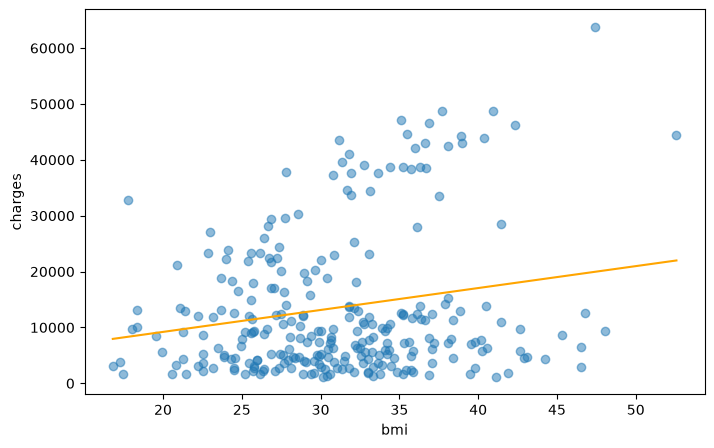

In [19]:
fig, ax = plt.subplots(figsize=(8, 5))

ax.scatter(
    x_test,
    y_test_array,
    alpha=0.5,
)

ax.plot(
    x_test[orden],
    predicciones[orden],
    color="orange",
)

ax.set_xlabel("bmi")
ax.set_ylabel("charges")

display(fig)
plt.close(fig)

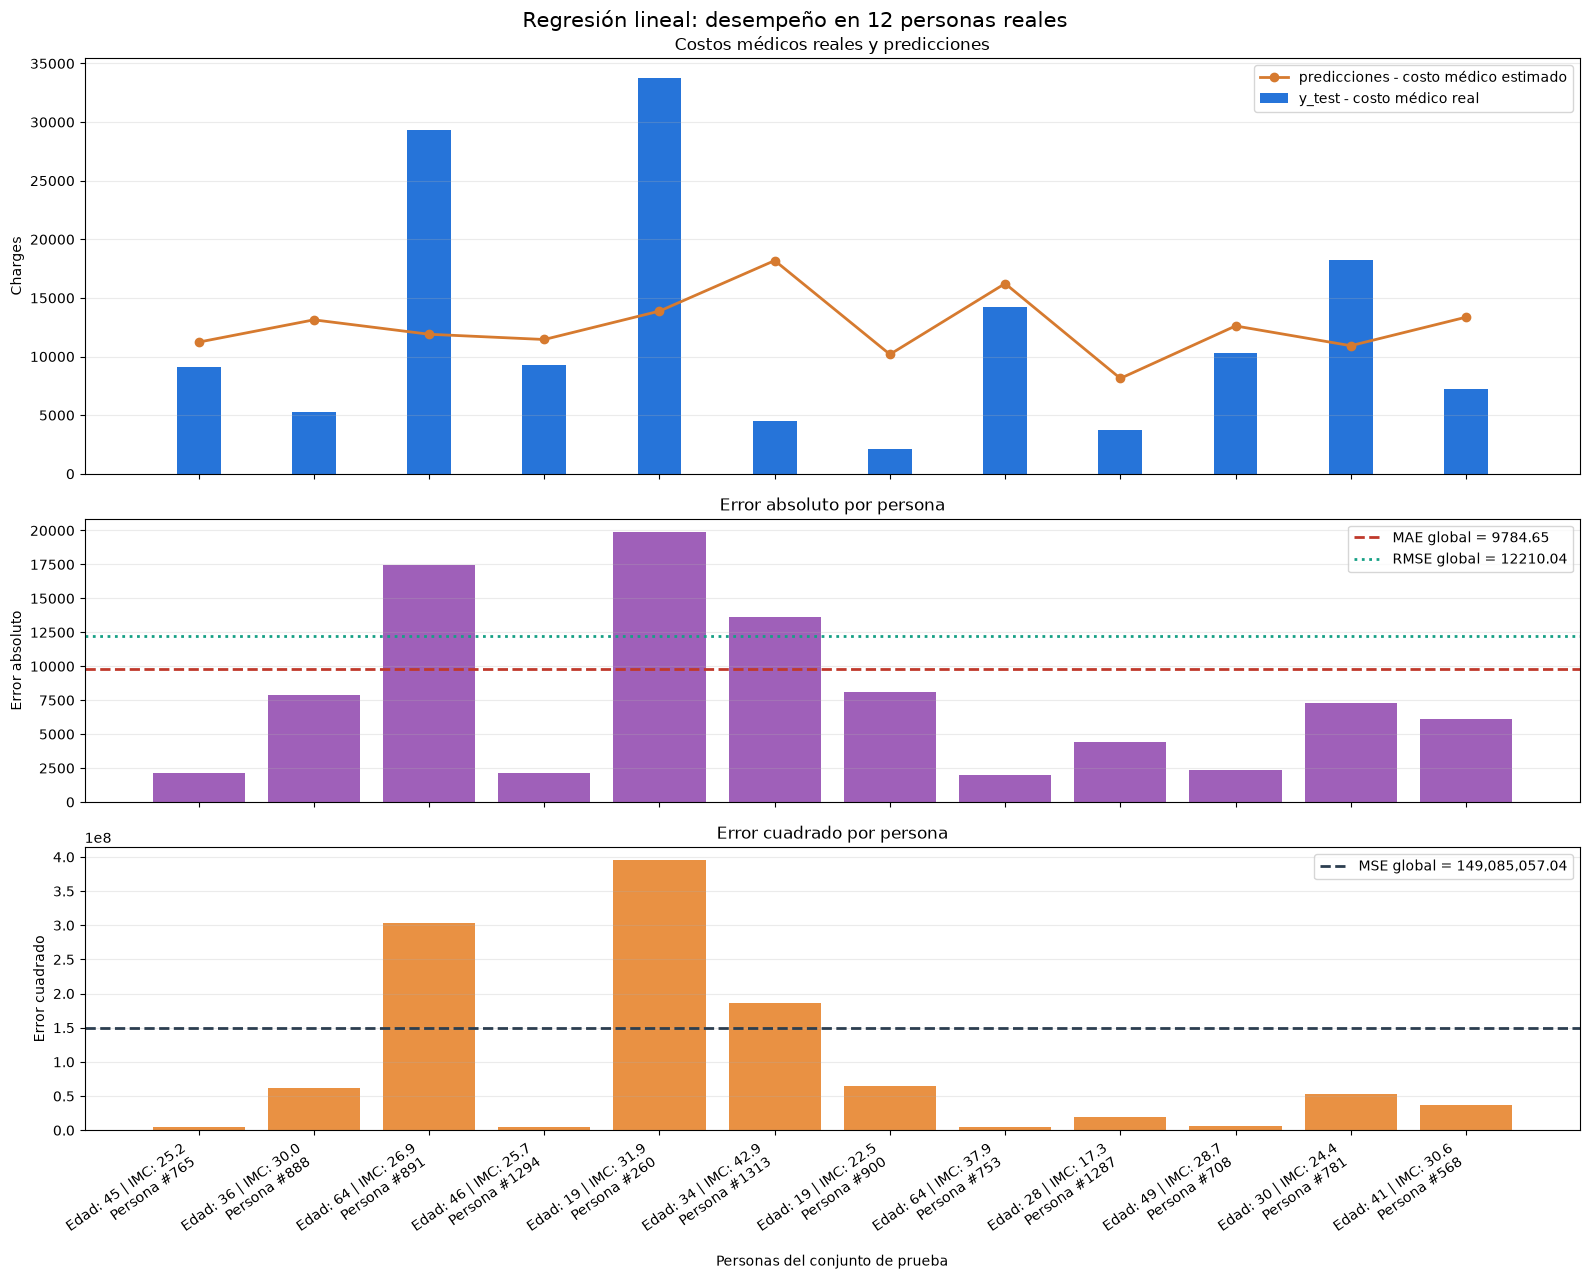

Personas mostradas: 12 de 268
Métricas globales - MAE: 9784.65; RMSE: 12210.04; MSE: 149,085,057.04
Métricas de la selección - MAE: 7781.53; RMSE: 9751.32; MSE: 95,088,331.01


In [20]:
# Comparación combinada para una selección legible de personas
# del dataset Medical Insurance

import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error, mean_squared_error

indices_test = y_test.index.to_numpy()
y_test_array = y_test.to_numpy()
predicciones_array = np.asarray(predicciones)

# Se muestran 12 personas, manteniendo el orden del conjunto de prueba.
seleccion = np.arange(min(12, len(y_test_array)))

y_real = y_test_array[seleccion]
y_predicha = predicciones_array[seleccion]

errores = y_real - y_predicha
error_absoluto = np.abs(errores)
error_cuadrado = errores ** 2

# Identificar personas con información del dataset
etiquetas = [
    f"Edad: {df.loc[indices_test[i], 'age']} | "
    f"IMC: {df.loc[indices_test[i], 'bmi']:.1f}\n"
    f"Persona #{indices_test[i] + 1}"
    for i in seleccion
]

# Métricas globales
mae_global = mean_absolute_error(y_test_array, predicciones_array)
rmse_global = np.sqrt(mean_squared_error(y_test_array, predicciones_array))
mse_global = mean_squared_error(y_test_array, predicciones_array)

posiciones = np.arange(len(seleccion))
ancho = 0.38

# Crear las tres gráficas
fig, (ax_costos, ax_absoluto, ax_cuadrado) = plt.subplots(
    3, 1, figsize=(16, 13), sharex=True,
    gridspec_kw={"height_ratios": [2.2, 1.5, 1.5]},
)

# Arriba: costo médico real en barras y predicción como línea con puntos.
ax_costos.bar(
    posiciones, y_real, ancho,
    label="y_test - costo médico real",
    color="#2674d9"
)

ax_costos.plot(
    posiciones, y_predicha,
    color="#d67a2f",
    marker="o",
    linewidth=2,
    label="predicciones - costo médico estimado"
)

ax_costos.set_ylabel("Charges")
ax_costos.set_title("Costos médicos reales y predicciones")
ax_costos.legend()
ax_costos.grid(axis="y", alpha=0.25)

# En medio: errores absolutos y referencias globales del modelo.
ax_absoluto.bar(
    posiciones, error_absoluto,
    color="#8e44ad", alpha=0.85
)

ax_absoluto.axhline(
    mae_global,
    color="#c0392b",
    linestyle="--",
    linewidth=2,
    label=f"MAE global = {mae_global:.2f}"
)

ax_absoluto.axhline(
    rmse_global,
    color="#16a085",
    linestyle=":",
    linewidth=2,
    label=f"RMSE global = {rmse_global:.2f}"
)

ax_absoluto.set_ylabel("Error absoluto")
ax_absoluto.set_title("Error absoluto por persona")
ax_absoluto.legend()
ax_absoluto.grid(axis="y", alpha=0.25)

# Abajo: errores cuadrados y referencia global del MSE.
ax_cuadrado.bar(
    posiciones, error_cuadrado,
    color="#e67e22", alpha=0.85
)

ax_cuadrado.axhline(
    mse_global,
    color="#2c3e50",
    linestyle="--",
    linewidth=2,
    label=f"MSE global = {mse_global:,.2f}"
)

ax_cuadrado.set_ylabel("Error cuadrado")
ax_cuadrado.set_title("Error cuadrado por persona")
ax_cuadrado.legend()
ax_cuadrado.grid(axis="y", alpha=0.25)

# Etiquetas del eje X
ax_cuadrado.set_xticks(posiciones)
ax_cuadrado.set_xticklabels(
    etiquetas,
    rotation=35,
    ha="right"
)

ax_cuadrado.set_xlabel("Personas del conjunto de prueba")

fig.suptitle(
    f"Regresión lineal: desempeño en {len(seleccion)} personas reales",
    fontsize=15
)

fig.tight_layout()

display(fig)
plt.close(fig)

# Resultados
print(f"Personas mostradas: {len(seleccion)} de {len(y_test_array)}")

print(
    f"Métricas globales - MAE: {mae_global:.2f}; "
    f"RMSE: {rmse_global:.2f}; "
    f"MSE: {mse_global:,.2f}"
)

print(
    f"Métricas de la selección - "
    f"MAE: {error_absoluto.mean():.2f}; "
    f"RMSE: {np.sqrt(error_cuadrado.mean()):.2f}; "
    f"MSE: {error_cuadrado.mean():,.2f}"
)

Filas: 1338 | duplicados exactos: 1
Valores faltantes por columna:
Sin valores faltantes


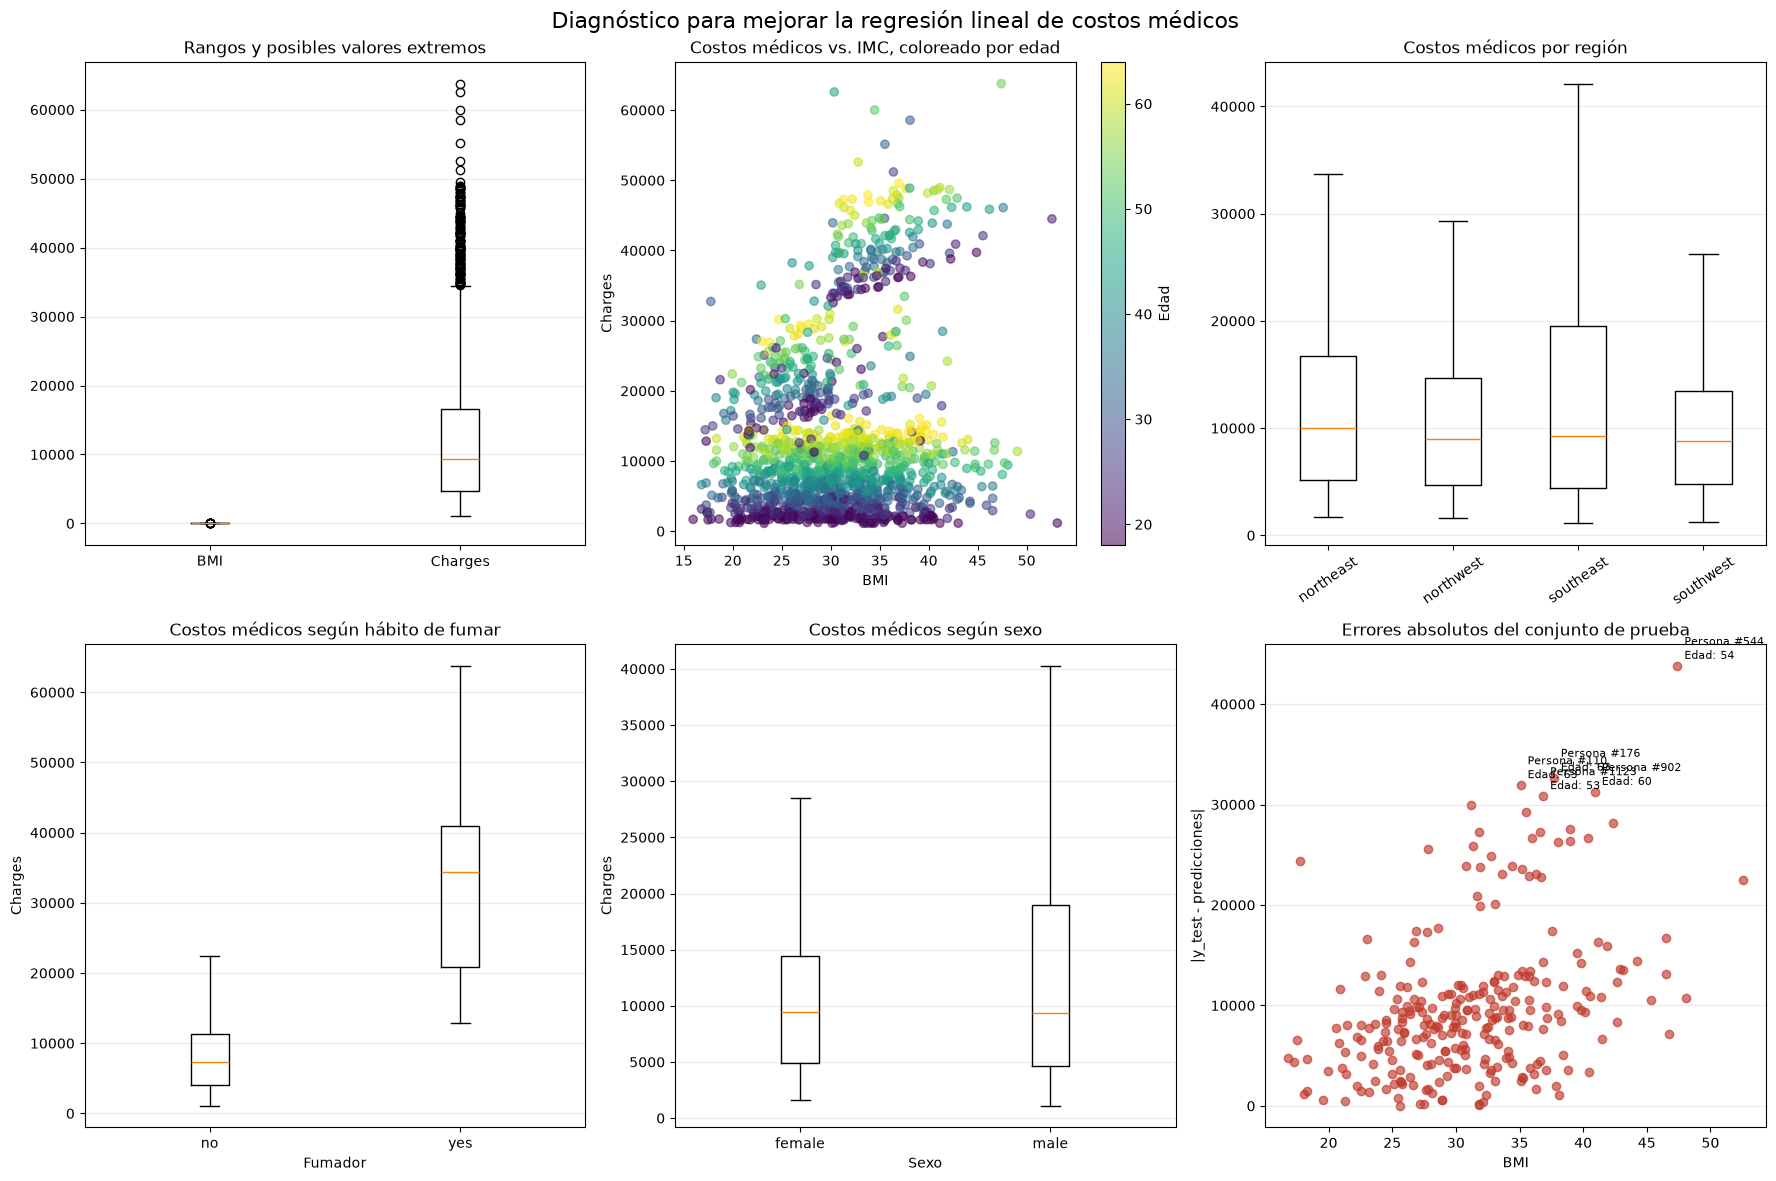


Mayores errores absolutos del conjunto de prueba:
      age     sex    bmi  children smoker     region       y_test  predicciones  error_absoluto
543    54  female  47.41         0    yes  southeast  63770.42801  19958.489631    43811.938379
175    63  female  37.70         0    yes  southwest  48824.45000  16147.930787    32676.519213
109    63    male  35.09         0    yes  southeast  47055.53210  15123.671407    31931.860693
901    60    male  40.92         0    yes  southeast  48673.55880  17411.576460    31261.982340
1122   53  female  36.86         3    yes  northwest  46661.44240  15818.284090    30843.158310

Cobertura de categorías:
sex: 2 categorías | mínimo por categoría: 662 | máximo por categoría: 676
smoker: 2 categorías | mínimo por categoría: 274 | máximo por categoría: 1064
region: 4 categorías | mínimo por categoría: 324 | máximo por categoría: 364


In [21]:
# Diagnóstico visual para decidir cómo mejorar el modelo
# Dataset: Medical Insurance

import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Columnas del dataset
columnas_requeridas = [
    "age", "sex", "bmi", "children",
    "smoker", "region", "charges"
]

columnas_disponibles = [
    columna for columna in columnas_requeridas
    if columna in df.columns
]

# Revisar duplicados y valores faltantes
filas_duplicadas = int(df.duplicated().sum())
valores_faltantes = df[columnas_disponibles].isna().sum()

print(f"Filas: {len(df)} | duplicados exactos: {filas_duplicadas}")

print("Valores faltantes por columna:")
print(
    valores_faltantes[valores_faltantes > 0]
    if valores_faltantes.any()
    else "Sin valores faltantes"
)

# Preparar el conjunto de prueba para investigar errores
indices_test = y_test.index.to_numpy()

prueba = df.loc[indices_test, columnas_disponibles].copy(deep=True)

prueba["y_test"] = y_test.to_numpy()
prueba["predicciones"] = np.asarray(predicciones)

prueba.loc[:, "error_absoluto"] = np.abs(
    prueba["y_test"] - prueba["predicciones"]
)

prueba.loc[:, "error_cuadrado"] = (
    prueba["y_test"] - prueba["predicciones"]
) ** 2

# Crear las seis gráficas
fig, axes = plt.subplots(2, 3, figsize=(18, 12))

# 1. Revisar rangos y posibles valores extremos
axes[0, 0].boxplot(
    [
        df["bmi"].dropna(),
        df["charges"].dropna()
    ],
    tick_labels=["BMI", "Charges"],
    showfliers=True
)

axes[0, 0].set_title("Rangos y posibles valores extremos")
axes[0, 0].grid(axis="y", alpha=0.25)

# 2. Comprobar la relación entre IMC, costos médicos y edad
scatter = axes[0, 1].scatter(
    df["bmi"],
    df["charges"],
    c=df["age"],
    cmap="viridis",
    alpha=0.55
)

axes[0, 1].set_title(
    "Costos médicos vs. IMC, coloreado por edad"
)

axes[0, 1].set_xlabel("BMI")
axes[0, 1].set_ylabel("Charges")

fig.colorbar(
    scatter,
    ax=axes[0, 1],
    label="Edad"
)

# 3. Comparar costos médicos entre regiones
regiones = sorted(df["region"].dropna().unique())

axes[0, 2].boxplot(
    [
        df.loc[df["region"] == region, "charges"].dropna()
        for region in regiones
    ],
    tick_labels=regiones,
    showfliers=False
)

axes[0, 2].set_title("Costos médicos por región")
axes[0, 2].tick_params(axis="x", rotation=35)
axes[0, 2].grid(axis="y", alpha=0.25)

# 4. Comparar costos médicos entre fumadores y no fumadores
fumadores = sorted(df["smoker"].dropna().unique())

axes[1, 0].boxplot(
    [
        df.loc[df["smoker"] == tipo, "charges"].dropna()
        for tipo in fumadores
    ],
    tick_labels=fumadores,
    showfliers=False
)

axes[1, 0].set_title("Costos médicos según hábito de fumar")
axes[1, 0].set_xlabel("Fumador")
axes[1, 0].set_ylabel("Charges")
axes[1, 0].grid(axis="y", alpha=0.25)

# 5. Comparar costos médicos según sexo
sexos = sorted(df["sex"].dropna().unique())

axes[1, 1].boxplot(
    [
        df.loc[df["sex"] == sexo, "charges"].dropna()
        for sexo in sexos
    ],
    tick_labels=sexos,
    showfliers=False
)

axes[1, 1].set_title("Costos médicos según sexo")
axes[1, 1].set_xlabel("Sexo")
axes[1, 1].set_ylabel("Charges")
axes[1, 1].grid(axis="y", alpha=0.25)

# 6. Localizar las personas que el modelo predice peor
prueba_ordenada = prueba.sort_values(
    "error_absoluto",
    ascending=False
)

axes[1, 2].scatter(
    prueba["bmi"],
    prueba["error_absoluto"],
    color="#c0392b",
    alpha=0.65
)

axes[1, 2].set_title(
    "Errores absolutos del conjunto de prueba"
)

axes[1, 2].set_xlabel("BMI")
axes[1, 2].set_ylabel("|y_test - predicciones|")
axes[1, 2].grid(axis="y", alpha=0.25)

# Identificar los cinco mayores errores
for indice, fila in prueba_ordenada.head(5).iterrows():

    axes[1, 2].annotate(
        f"Persona #{indice + 1}\nEdad: {fila['age']}",
        (fila["bmi"], fila["error_absoluto"]),
        xytext=(5, 5),
        textcoords="offset points",
        fontsize=8
    )

# Título general
fig.suptitle(
    "Diagnóstico para mejorar la regresión lineal de costos médicos",
    fontsize=16
)

fig.tight_layout()

display(fig)
plt.close(fig)

# Mostrar los cinco mayores errores
print("\nMayores errores absolutos del conjunto de prueba:")

print(
    prueba_ordenada[
        [
            "age",
            "sex",
            "bmi",
            "children",
            "smoker",
            "region",
            "y_test",
            "predicciones",
            "error_absoluto"
        ]
    ]
    .head(5)
    .to_string()
)

# Cobertura de categorías
print("\nCobertura de categorías:")

for columna in ["sex", "smoker", "region"]:

    conteos = df[columna].value_counts()

    print(
        f"{columna}: {df[columna].nunique()} categorías | "
        f"mínimo por categoría: {conteos.min()} | "
        f"máximo por categoría: {conteos.max()}"
    )

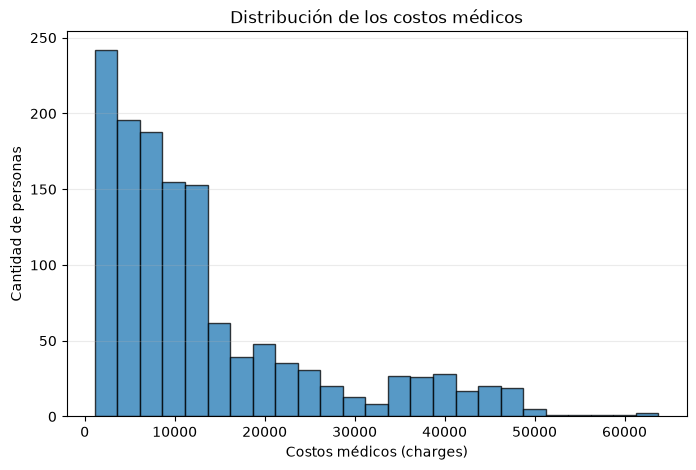

In [22]:
fig, ax = plt.subplots(figsize=(8, 5))

ax.hist(
    df["charges"],
    bins=25,
    edgecolor="black",
    alpha=0.75
)

ax.set_title("Distribución de los costos médicos")
ax.set_xlabel("Costos médicos (charges)")
ax.set_ylabel("Cantidad de personas")
ax.grid(axis="y", alpha=0.25)

display(fig)
plt.close(fig)

### Importar la clase

In [23]:
from clases_po import RegresionLineal

### Inicializar el modelo

In [24]:
regresion_simple = RegresionLineal(
    feature_column="bmi",
    target_column="charges",
    test_size=0.2,
    random_state=42
)

resultado_simple = regresion_simple.ejecutar(df=df)

[ejecutar][1/6] Iniciando preparar_datos.
[preparar_datos] X=['bmi'], y='charges'; 1338 filas válidas; 0 filas eliminadas; X=(1338, 1), y=(1338,).
[ejecutar][2/6] Iniciando dividir_datos.
[dividir_datos] test_size=0.20; random_state=42; entrenamiento=1070 filas (1070, 1); prueba=268 filas (268, 1).
[dividir_datos] salida: X_train/y_train entrenan el modelo; X_test/y_test miden su rendimiento con datos no vistos.
[ejecutar][3/6] Iniciando entrenar.
[entrenar] modelo ajustado con 1070 filas y 1 características.
[entrenar] modelo guardado en: entrenamiento/20261022_063342_830790_modelo.pkl
[ejecutar][4/6] Iniciando predecir.
[predecir] modelo cargado desde entrenamiento/20261022_063342_830790_modelo.pkl; 268 predicciones generadas.
[ejecutar][5/6] Iniciando obtener_parametros.
[obtener_parametros] modelo cargado desde entrenamiento/20261022_063342_830790_modelo.pkl; w=392.43654416987977; b=1353.0731.
[ejecutar][6/6] Iniciando evaluar.
[predecir] modelo cargado desde entrenamiento/20261022

### Preparar los datos

In [25]:
X2, y2 = regresion_simple.preparar_datos(
    df=df, X_columnas=["age", "bmi"], y_objetivo="charges")

[preparar_datos] X=['age', 'bmi'], y='charges'; 1338 filas válidas; 0 filas eliminadas; X=(1338, 2), y=(1338,).


### Dividir los datos

In [26]:
X2_train, X2_test, y2_train, y2_test = regresion_simple.dividir_datos(
    X=X2,
    y=y2,
    test_size=0.2,
    random_state=42
)

[dividir_datos] test_size=0.20; random_state=42; entrenamiento=1070 filas (1070, 2); prueba=268 filas (268, 2).
[dividir_datos] salida: X_train/y_train entrenan el modelo; X_test/y_test miden su rendimiento con datos no vistos.


### Entrenar el modelo

In [27]:
datos_entrenamiento = regresion_simple.entrenar(
    X_train=X2_train,
    y_train=y2_train,
    directorio_entrenamiento="entrenamiento"
)

[entrenar] modelo ajustado con 1070 filas y 2 características.
[entrenar] modelo guardado en: entrenamiento/20261022_063347_232942_modelo.pkl


In [28]:
datos_entrenamiento["ruta_modelo"]

PosixPath('entrenamiento/20261022_063347_232942_modelo.pkl')

In [29]:
algo=regresion_simple.ejecutar(df=df)

[ejecutar][1/6] Iniciando preparar_datos.
[preparar_datos] X=['age', 'bmi'], y='charges'; 1338 filas válidas; 0 filas eliminadas; X=(1338, 2), y=(1338,).
[ejecutar][2/6] Iniciando dividir_datos.
[dividir_datos] test_size=0.20; random_state=42; entrenamiento=1070 filas (1070, 2); prueba=268 filas (268, 2).
[dividir_datos] salida: X_train/y_train entrenan el modelo; X_test/y_test miden su rendimiento con datos no vistos.
[ejecutar][3/6] Iniciando entrenar.
[entrenar] modelo ajustado con 1070 filas y 2 características.
[entrenar] modelo guardado en: entrenamiento/20261022_063348_587564_modelo.pkl
[ejecutar][4/6] Iniciando predecir.
[predecir] modelo cargado desde entrenamiento/20261022_063348_587564_modelo.pkl; 268 predicciones generadas.
[ejecutar][5/6] Iniciando obtener_parametros.
[obtener_parametros] modelo cargado desde entrenamiento/20261022_063348_587564_modelo.pkl; w=[223.79653146380315, 330.7944886846065]; b=-5571.0834.
[ejecutar][6/6] Iniciando evaluar.
[predecir] modelo cargado

### Multiple

In [30]:
regresion_multiple = RegresionLineal(
    feature_column=["age", "bmi"],
    target_column="charges",
    test_size=0.2,
    random_state=42
)

resultado_multiple = regresion_multiple.ejecutar(df=df)

[ejecutar][1/6] Iniciando preparar_datos.
[preparar_datos] X=['age', 'bmi'], y='charges'; 1338 filas válidas; 0 filas eliminadas; X=(1338, 2), y=(1338,).
[ejecutar][2/6] Iniciando dividir_datos.
[dividir_datos] test_size=0.20; random_state=42; entrenamiento=1070 filas (1070, 2); prueba=268 filas (268, 2).
[dividir_datos] salida: X_train/y_train entrenan el modelo; X_test/y_test miden su rendimiento con datos no vistos.
[ejecutar][3/6] Iniciando entrenar.
[entrenar] modelo ajustado con 1070 filas y 2 características.
[entrenar] modelo guardado en: entrenamiento/20261022_063350_047167_modelo.pkl
[ejecutar][4/6] Iniciando predecir.
[predecir] modelo cargado desde entrenamiento/20261022_063350_047167_modelo.pkl; 268 predicciones generadas.
[ejecutar][5/6] Iniciando obtener_parametros.
[obtener_parametros] modelo cargado desde entrenamiento/20261022_063350_047167_modelo.pkl; w=[223.79653146380315, 330.7944886846065]; b=-5571.0834.
[ejecutar][6/6] Iniciando evaluar.
[predecir] modelo cargado

In [31]:
print("R² regresión simple:",
      resultado_simple["metricas"]["r2"])

print("R² regresión múltiple:",
      resultado_multiple["metricas"]["r2"])

R² regresión simple: 0.03970193117941878
R² regresión múltiple: 0.1533569292467798
